# 03 · K-means clustering (unsupervised)

K-means **doesn't use the fraud labels** when it learns. It just groups similar transactions. The question is: do the groups line up with fraud?

Spoiler: mostly no — and understanding *why* is a good interview answer.

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))   # so we can import src/utils.py

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

from src.utils import *   # load_data, time_split, make_preprocessor, evaluate, ...

RANDOM_STATE = 42
plt.rcParams["figure.figsize"] = (8, 4.5)

In [2]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import average_precision_score

df = load_data()
train, val, test = time_split(df)

prep = make_preprocessor().fit(train[FEATURES])     # learn scaling from TRAIN only
Xtr, Xva, Xte = (prep.transform(d[FEATURES]) for d in (train, val, test))
print(Xtr.shape)

(175090, 34)


## 1. K-means with 2 clusters (the naive approach)

The original project assumed "cluster 1 = fraud". But cluster numbers are random — cluster 1 is just whichever group K-means happened to label 1. Here we map each cluster to the label that is **most common in it on the training data**.

In [3]:
km2 = KMeans(n_clusters=2, n_init=10, random_state=RANDOM_STATE).fit(Xtr)
train_clusters = km2.labels_
fraud_rate_per_cluster = pd.Series(train[TARGET].values).groupby(train_clusters).mean()
print("Fraud rate in each cluster (train):"); print(fraud_rate_per_cluster)
fraud_cluster = fraud_rate_per_cluster.idxmax()
print(f"\nWe call cluster {fraud_cluster} the 'fraud' cluster")

Fraud rate in each cluster (train):
0    0.001320
1    0.006177
dtype: float64

We call cluster 1 the 'fraud' cluster


--- K-means (k=2) ---
                accuracy: 0.7547
               precision: 0.0062
   recall (fraud caught): 0.5625
                      f1: 0.0123
     false_negative_rate: 0.4375
           frauds_missed: 49
            false_alarms: 10,102
                cost_gbp: 51,345.8900


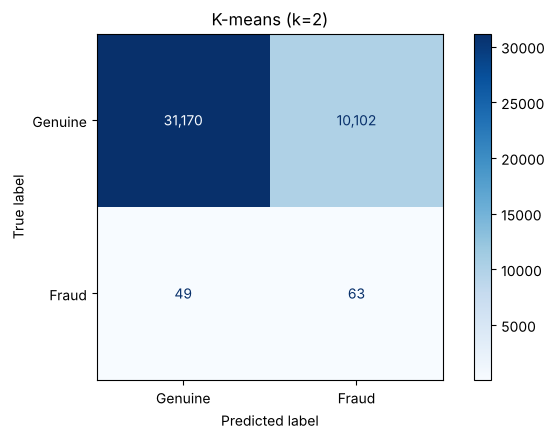

In [4]:
pred_test = (km2.predict(Xte) == fraud_cluster).astype(int)
_ = evaluate("K-means (k=2)", test[TARGET], pred_test, amounts=test["amount_gbp"])

Fraud is only 0.25% of the data, so it can't form its own big cluster. K-means splits the data along the **biggest** differences (e.g. online vs in-store), not along fraud vs genuine. So one cluster ends up with a slightly higher fraud rate and loads of false alarms.

## 2. Visualise with PCA

PCA squashes all the features down to 2 dimensions just so we can draw them. (We fit PCA on training data, then apply it to the rest — the original project re-fitted PCA on the test set, which scrambles the axes.)

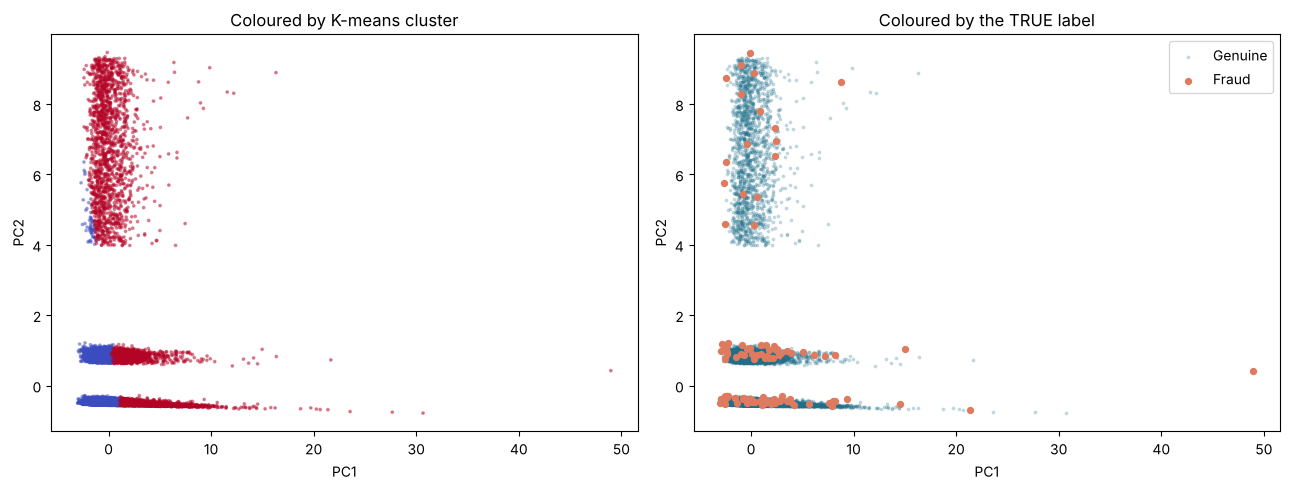

These 2 components explain 28.1% of the variation


In [5]:
pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(Xtr)
P = pca.transform(Xte)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(P[:, 0], P[:, 1], c=km2.predict(Xte), s=3, cmap="coolwarm", alpha=0.4)
axes[0].set_title("Coloured by K-means cluster")
g = test[TARGET].values == 0
axes[1].scatter(P[g, 0], P[g, 1], s=3, c="#1f6f8b", alpha=0.2, label="Genuine")
axes[1].scatter(P[~g, 0], P[~g, 1], s=18, c="#e07a5f", label="Fraud")
axes[1].set_title("Coloured by the TRUE label"); axes[1].legend()
for a in axes: a.set_xlabel("PC1"); a.set_ylabel("PC2")
plt.tight_layout(); plt.savefig("../images/kmeans_pca.png", dpi=120, bbox_inches="tight"); plt.show()
print(f"These 2 components explain {pca.explained_variance_ratio_.sum():.1%} of the variation")

The clusters (left) clearly don't match where the fraud is (right).

## 3. A better way to use K-means: anomaly score

Instead of "which cluster?", ask "**how far is this payment from the nearest cluster centre?**". Unusual payments sit far away. We use more clusters (normal behaviour has many shapes) and treat the distance as a fraud score.

In [6]:
rows = []
for k in [2, 4, 8, 12, 16]:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Xtr)
    dist_val = km.transform(Xva).min(axis=1)        # distance to nearest centre
    rows.append({"k": k, "val_pr_auc": average_precision_score(val[TARGET], dist_val)})
k_table = pd.DataFrame(rows); k_table

,k,val_pr_auc
0,2,0.096850
1,4,0.106499
2,8,0.146378
3,12,0.197606
4,16,0.218953


k=16, threshold=0.64
--- K-means distance (k=16) ---
                accuracy: 0.9934
               precision: 0.1970
   recall (fraud caught): 0.4732
                      f1: 0.2782
     false_negative_rate: 0.5268
           frauds_missed: 59
            false_alarms: 216
                  pr_auc: 0.1825
                 roc_auc: 0.9347
                cost_gbp: 5,038.2200


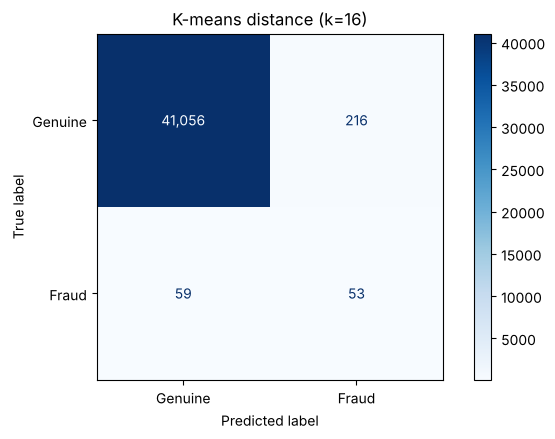

In [7]:
best_k = int(k_table.sort_values("val_pr_auc", ascending=False).iloc[0]["k"])
km = KMeans(n_clusters=best_k, n_init=10, random_state=RANDOM_STATE).fit(Xtr)
d_val, d_test = km.transform(Xva).min(axis=1), km.transform(Xte).min(axis=1)

# turn distance into a 0-1 score so we can reuse the same threshold search
scale_max = np.percentile(km.transform(Xtr).min(axis=1), 99.9)
s_val, s_test = np.clip(d_val / scale_max, 0, 1), np.clip(d_test / scale_max, 0, 1)
threshold = best_threshold(val[TARGET], s_val, val["amount_gbp"])
print(f"k={best_k}, threshold={threshold}")
km_results = evaluate(f"K-means distance (k={best_k})", test[TARGET], (s_test >= threshold).astype(int),
                      s_test, test["amount_gbp"])

In [8]:
import json, os
os.makedirs("../results", exist_ok=True)
json.dump({k: (float(v) if not isinstance(v, str) else v) for k, v in km_results.items()},
          open("../results/kmeans.json", "w"), indent=2)

## Summary
- K-means with 2 clusters doesn't find fraud: the clusters follow the biggest patterns in the data, and fraud is too rare to be one.
- Using **distance from the nearest centre** as an anomaly score works better, but is still far weaker than supervised models — because it never sees the labels.
- When would you use it? When you have **no fraud labels** (e.g. a brand-new product) — it's a starting point for flagging unusual activity for humans to review.